# Sneha Singh
## DATA 266 — Homework 10
Improving RAG with Reranking, Chunking, and Conversational Memory

This notebook loads the first 100 `document` train articles from `ccdv/arxiv-summarization`, builds two chunk indexes in ChromaDB, compares retrieval with and without a cross-encoder reranker, adds a small conversational memory, and scores Precision@K, Recall@K, and MRR.


In [1]:
# Step 0: Libraries & Student Parameters
import os
import re
import math
import json
import random
import shutil
import time
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import chromadb
from chromadb.utils import embedding_functions
from datasets import load_dataset
from langchain_text_splitters import CharacterTextSplitter, RecursiveCharacterTextSplitter
from sentence_transformers import CrossEncoder

# last 4 of my SJSUid - 0670
SEED = 670
random.seed(SEED)
np.random.seed(SEED)

SID4 = 670
SLICE = 670
HP_ID = 4
CLS_A = 0
CLS_B = 5

N_DOCS = 100
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
RERANK_MODEL = "cross-encoder/ms-marco-MiniLM-L-6-v2"
TOP_N = 20
TOP_K = 5
CHUNK_SIZE = 500
CHUNK_OVERLAP = 50

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
os.makedirs("data", exist_ok=True)
CHROMA_DIR = "chroma_store"
if os.path.isdir(CHROMA_DIR):
    shutil.rmtree(CHROMA_DIR)

print("SID4: %04d" % SID4)
print("SEED:", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID, "(reported only)")
print("CLS_A:", CLS_A, "CLS_B:", CLS_B)


SID4: 0670
SEED: 670
SLICE: 670
HP_ID: 4 (reported only)
CLS_A: 0 CLS_B: 5


HP_ID is reported only. The two chunking strategies below are fixed-size and recursive character splitting. The vector store is local ChromaDB. The reranker is a free cross-encoder, not a paid API.


## 1. Data and preprocessing

I load `ccdv/arxiv-summarization`, the `document` config, and keep the first 100 training articles. Each row has an `article` and an `abstract`. I clean the `@xmath` / `@xcite` tokens a little so the chunks are readable, but I do not pre-chunk beyond the two strategies in the next section.


In [2]:
# load the first 100 document-train articles
raw = load_dataset("ccdv/arxiv-summarization", "document", split=f"train[:{N_DOCS}]")
print("rows:", len(raw))
print("columns:", raw.column_names)

def clean_text(text):
    text = re.sub(r"@xmath\d+", " ", text)
    text = re.sub(r"@xcite", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

docs = []
for i in range(len(raw)):
    article = clean_text(raw[i]["article"])
    abstract = clean_text(raw[i]["abstract"])
    docs.append({
        "doc_id": i,
        "article": article,
        "abstract": abstract,
        "title_proxy": abstract[:120],
    })

lengths = [len(d["article"]) for d in docs]
print(f"article chars: min={min(lengths)} mean={sum(lengths)/len(lengths):.0f} max={max(lengths)}")
print("doc 0 abstract:", docs[0]["abstract"][:220])


rows: 100
columns: ['article', 'abstract']
article chars: min=2695 mean=32335 max=161248
doc 0 abstract: additive models play an important role in semiparametric statistics . this paper gives learning rates for regularized kernel based methods for additive models . these learning rates compare favourably in particular in hi


## 2. Two chunking strategies

Strategy A is fixed-size character chunks (500 / 50). Strategy B is recursive character splitting with the same size, so separators can keep sentences together more often. That matches Level 1 and Level 2 from the lecture.


In [3]:
# build two chunk lists from the same 100 articles
fixed_splitter = CharacterTextSplitter(
    separator="",
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
)
recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
)

def make_chunks(splitter, tag):
    chunks = []
    for doc in docs:
        pieces = splitter.split_text(doc["article"])
        for j, text in enumerate(pieces):
            chunks.append({
                "id": f"{tag}-{doc['doc_id']}-{j}",
                "text": text,
                "doc_id": doc["doc_id"],
                "chunk_id": j,
                "strategy": tag,
            })
    return chunks

chunks_fixed = make_chunks(fixed_splitter, "fixed")
chunks_recursive = make_chunks(recursive_splitter, "recursive")
print("fixed chunks:", len(chunks_fixed))
print("recursive chunks:", len(chunks_recursive))
print("fixed sample:", chunks_fixed[0]["text"][:160].replace("\n", " "))
print("recursive sample:", chunks_recursive[0]["text"][:160].replace("\n", " "))


fixed chunks: 7220
recursive chunks: 7224
fixed sample: additive models provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are thei
recursive sample: additive models provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are thei


## 3. Embeddings and ChromaDB

I embed with `all-MiniLM-L6-v2` and store one Chroma collection per chunking strategy. The store is local under `chroma_store/`.


In [4]:
# embed and index both chunk sets in Chroma
embed_fn = embedding_functions.SentenceTransformerEmbeddingFunction(model_name=EMBED_MODEL)
client = chromadb.PersistentClient(path=CHROMA_DIR)

def build_collection(name, chunks):
    if name in [c.name for c in client.list_collections()]:
        client.delete_collection(name)
    coll = client.create_collection(name=name, embedding_function=embed_fn, metadata={"hnsw:space": "cosine"})
    batch = 64
    for start in range(0, len(chunks), batch):
        part = chunks[start:start + batch]
        coll.add(
            ids=[c["id"] for c in part],
            documents=[c["text"] for c in part],
            metadatas=[{"doc_id": c["doc_id"], "chunk_id": c["chunk_id"], "strategy": c["strategy"]} for c in part],
        )
        if (start // batch) % 20 == 0:
            print(f"{name}: indexed {min(start + batch, len(chunks))}/{len(chunks)}")
    return coll

t0 = time.perf_counter()
coll_fixed = build_collection("arxiv_fixed", chunks_fixed)
coll_recursive = build_collection("arxiv_recursive", chunks_recursive)
print(f"indexing minutes: {(time.perf_counter() - t0) / 60:.2f}")
print("fixed count:", coll_fixed.count())
print("recursive count:", coll_recursive.count())


arxiv_fixed: indexed 64/7220
arxiv_fixed: indexed 1344/7220
arxiv_fixed: indexed 2624/7220
arxiv_fixed: indexed 3904/7220
arxiv_fixed: indexed 5184/7220
arxiv_fixed: indexed 6464/7220
arxiv_recursive: indexed 64/7224
arxiv_recursive: indexed 1344/7224
arxiv_recursive: indexed 2624/7224
arxiv_recursive: indexed 3904/7224
arxiv_recursive: indexed 5184/7224
arxiv_recursive: indexed 6464/7224
indexing minutes: 3.02
fixed count: 7220
recursive count: 7224


## 4. Queries, baseline retrieval, and reranking

I use two content queries plus one follow-up that depends on the first answer. Baseline retrieval is embedding top-5. Reranked retrieval pulls top-20 by embedding, then a cross-encoder (`ms-marco-MiniLM-L-6-v2`) reorders them and keeps top-5.


In [5]:
# sample queries and a dependent follow-up
QUERIES = {
    "Q1": "learning rates for regularized kernel based methods for additive models",
    "Q2": "positive linear magnetoresistance in topological insulator surface states",
    "Q3_followup": "What learning rates does the paper report?",
}

# gold relevant documents for the metrics (manual judgment from abstracts)
GOLD = {
    "Q1": {0},
    "Q2": {20},
    "Q3_followup": {0},
    "Q3_with_memory": {0},
}

reranker = CrossEncoder(RERANK_MODEL)

def retrieve(collection, query, n=TOP_K):
    out = collection.query(query_texts=[query], n_results=n, include=["documents", "metadatas", "distances"])
    rows = []
    for i in range(len(out["ids"][0])):
        rows.append({
            "id": out["ids"][0][i],
            "text": out["documents"][0][i],
            "doc_id": int(out["metadatas"][0][i]["doc_id"]),
            "distance": float(out["distances"][0][i]),
            "score": 1.0 - float(out["distances"][0][i]),
        })
    return rows

def rerank(query, rows, keep=TOP_K):
    if not rows:
        return []
    pairs = [(query, r["text"]) for r in rows]
    scores = reranker.predict(pairs)
    ranked = sorted(
        [{**r, "rerank_score": float(s)} for r, s in zip(rows, scores)],
        key=lambda x: x["rerank_score"],
        reverse=True,
    )
    return ranked[:keep]

def show_hits(title, rows):
    print(f"\n=== {title} ===")
    for i, r in enumerate(rows, 1):
        snip = r["text"][:110].replace("\n", " ")
        extra = f" rerank={r['rerank_score']:.3f}" if "rerank_score" in r else f" sim={r['score']:.3f}"
        print(f"{i}. doc={r['doc_id']}{extra} | {snip}")

# baseline and reranked results on both chunk indexes
results = {}
for strategy, coll in [("fixed", coll_fixed), ("recursive", coll_recursive)]:
    for qid in ("Q1", "Q2"):
        q = QUERIES[qid]
        base = retrieve(coll, q, n=TOP_K)
        broad = retrieve(coll, q, n=TOP_N)
        ranked = rerank(q, broad, keep=TOP_K)
        results[(strategy, qid, "base")] = base
        results[(strategy, qid, "rerank")] = ranked
        show_hits(f"{strategy} | {qid} | no rerank", base)
        show_hits(f"{strategy} | {qid} | rerank", ranked)



=== fixed | Q1 | no rerank ===
1. doc=0 sim=0.800 | . in this paper we provide some learning rates for the support vector machines generated by additive kernels f
2. doc=0 sim=0.777 | estimators in fully nonparametric models . many examples of such estimators belong to the large class of regul
3. doc=0 sim=0.741 | ch regularized kernel based methods are now often called support vector machines ( svms ) , although the notat
4. doc=0 sim=0.732 | ditive model is satisfied because this would be a topic of a paper of its own . of course , a practical approa
5. doc=0 sim=0.698 | d ( often ) a reduced proneness of the curse of high dimensions . hence it is important to check , whether the

=== fixed | Q1 | rerank ===
1. doc=0 rerank=6.560 | estimators in fully nonparametric models . many examples of such estimators belong to the large class of regul
2. doc=0 rerank=6.129 | . in this paper we provide some learning rates for the support vector machines generated by additive kernels f
3. doc=0 

## 5. Conversational memory

I keep a short list of prior turns. For the follow-up question I rewrite the query using the last user turn, so "What learning rates does the paper report?" becomes a question about additive-model kernel methods. That is the with-memory path. The without-memory path sends the bare follow-up to the retriever.


In [6]:
# simple turn memory and a dependent follow-up query
memory = []

def remember(role, text):
    memory.append({"role": role, "text": text})

def rewrite_with_memory(followup):
    prior_user = [m["text"] for m in memory if m["role"] == "user"]
    if not prior_user:
        return followup
    last = prior_user[-1]
    return f"Given the previous question about '{last}', answer this follow-up: {followup}"

# first turn: ask Q1 and store a short answer sketch from the top chunk
q1 = QUERIES["Q1"]
remember("user", q1)
q1_hits = rerank(q1, retrieve(coll_recursive, q1, n=TOP_N), keep=1)
sketch = q1_hits[0]["text"][:240] if q1_hits else "No hit."
remember("assistant", sketch)
print("memory after turn 1:")
for m in memory:
    print("-", m["role"] + ":", m["text"][:160].replace("\n", " "))

follow = QUERIES["Q3_followup"]
bare_hits = retrieve(coll_recursive, follow, n=TOP_K)
rewritten = rewrite_with_memory(follow)
memory_hits_base = retrieve(coll_recursive, rewritten, n=TOP_K)
memory_hits = rerank(rewritten, retrieve(coll_recursive, rewritten, n=TOP_N), keep=TOP_K)
results[("recursive", "Q3_followup", "base")] = bare_hits
results[("recursive", "Q3_with_memory", "base")] = memory_hits_base
results[("recursive", "Q3_with_memory", "rerank")] = memory_hits

print("\nrewritten follow-up:")
print(rewritten)
show_hits("follow-up WITHOUT memory", bare_hits)
show_hits("follow-up WITH memory (reranked)", memory_hits)


memory after turn 1:
- user: learning rates for regularized kernel based methods for additive models
- assistant: estimators in fully nonparametric models . many examples of such estimators belong to the large class of regularized kernel based methods over a reproducing ker

rewritten follow-up:
Given the previous question about 'learning rates for regularized kernel based methods for additive models', answer this follow-up: What learning rates does the paper report?

=== follow-up WITHOUT memory ===
1. doc=0 sim=0.489 | further note that , if , and if . because can be arbitrarily close to , the learning rate , which is independe
2. doc=0 sim=0.462 | ] , if we take and for some , then for any , with confidence at least we have where is given by and is constan
3. doc=0 sim=0.451 | one in ( * ? ? ? 4.12 ) in this situation , if provided the assumption of the additive model is valid . table 
4. doc=0 sim=0.433 | ] under assumption [ assumption1 ] , we have where is the constant given by t

## 6. Evaluation

A retrieved chunk is relevant if its source `doc_id` is in the manual gold set for that query. Q1 and the memory follow-up use document 0. Q2 uses document 20. I report Precision@5, Recall@5, and MRR.


In [7]:
# Precision@K, Recall@K, and MRR from the manual gold doc ids
def precision_at_k(rows, gold, k=TOP_K):
    top = rows[:k]
    if not top:
        return 0.0
    hits = sum(1 for r in top if r["doc_id"] in gold)
    return hits / k

def recall_at_k(rows, gold, k=TOP_K):
    if not gold:
        return 0.0
    got = {r["doc_id"] for r in rows[:k] if r["doc_id"] in gold}
    return len(got) / len(gold)

def mrr(rows, gold):
    for i, r in enumerate(rows, 1):
        if r["doc_id"] in gold:
            return 1.0 / i
    return 0.0

rows_out = []
eval_keys = [
    ("fixed", "Q1", "base"),
    ("fixed", "Q1", "rerank"),
    ("fixed", "Q2", "base"),
    ("fixed", "Q2", "rerank"),
    ("recursive", "Q1", "base"),
    ("recursive", "Q1", "rerank"),
    ("recursive", "Q2", "base"),
    ("recursive", "Q2", "rerank"),
    ("recursive", "Q3_followup", "base"),
    ("recursive", "Q3_with_memory", "base"),
    ("recursive", "Q3_with_memory", "rerank"),
]

print(f"{'setting':45s} P@5   R@5   MRR")
for strategy, qid, mode in eval_keys:
    gold = GOLD[qid]
    hits = results[(strategy, qid, mode)]
    p = precision_at_k(hits, gold)
    r = recall_at_k(hits, gold)
    m = mrr(hits, gold)
    label = f"{strategy}/{qid}/{mode}"
    print(f"{label:45s} {p:.3f} {r:.3f} {m:.3f}")
    rows_out.append({
        "strategy": strategy,
        "query": qid,
        "mode": mode,
        "precision@5": round(p, 4),
        "recall@5": round(r, 4),
        "mrr": round(m, 4),
        "top_doc_ids": [h["doc_id"] for h in hits[:TOP_K]],
    })

with open("outputs/metrics.json", "w") as f:
    json.dump({"queries": QUERIES, "gold": {k: sorted(v) for k, v in GOLD.items()}, "rows": rows_out}, f, indent=2)
print("wrote outputs/metrics.json")


setting                                       P@5   R@5   MRR
fixed/Q1/base                                 1.000 1.000 1.000
fixed/Q1/rerank                               1.000 1.000 1.000
fixed/Q2/base                                 0.800 1.000 1.000
fixed/Q2/rerank                               1.000 1.000 1.000
recursive/Q1/base                             1.000 1.000 1.000
recursive/Q1/rerank                           1.000 1.000 1.000
recursive/Q2/base                             0.800 1.000 1.000
recursive/Q2/rerank                           1.000 1.000 1.000
recursive/Q3_followup/base                    0.800 1.000 1.000
recursive/Q3_with_memory/base                 1.000 1.000 1.000
recursive/Q3_with_memory/rerank               1.000 1.000 1.000
wrote outputs/metrics.json


## 7. Comparisons and figures

I compare fixed vs recursive chunking, no-rerank vs rerank, and the bare follow-up vs the memory-rewritten follow-up.


avg Precision@5 / MRR by setting:
  fixed no-rerank: P@5=0.900 MRR=1.000
  fixed rerank: P@5=1.000 MRR=1.000
  recursive no-rerank: P@5=0.900 MRR=1.000
  recursive rerank: P@5=1.000 MRR=1.000
follow-up MRR: {'follow-up no memory': 1.0, 'follow-up with memory': 1.0, 'follow-up memory+rerank': 1.0}


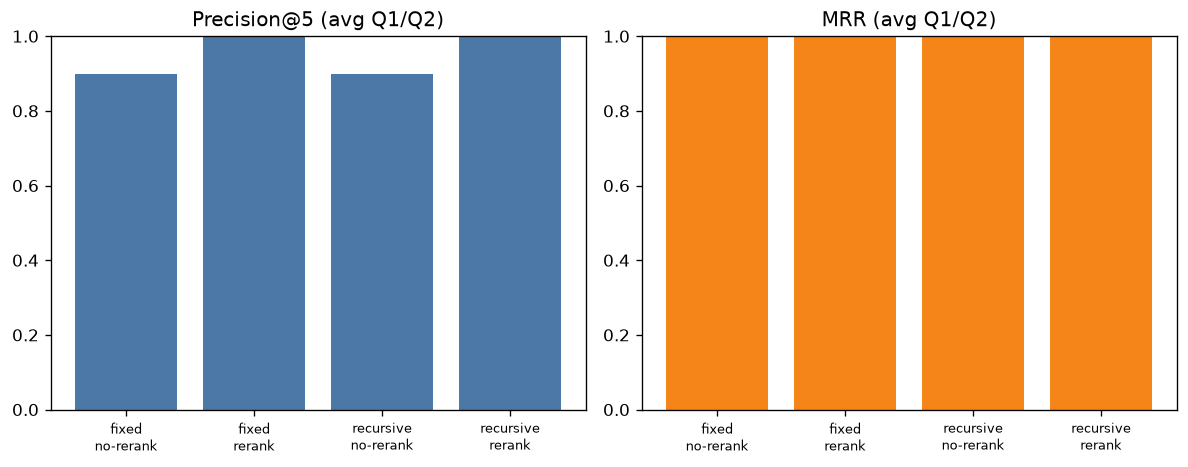

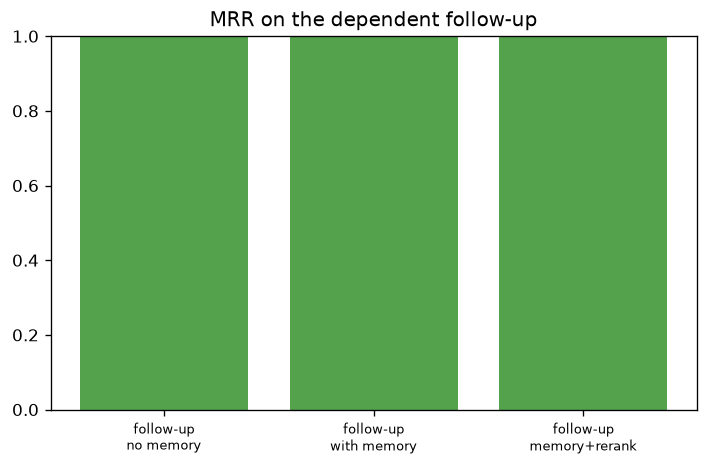

In [8]:
# bar chart for the main comparisons
def metric_map(strategy, qid, mode):
    for row in rows_out:
        if row["strategy"] == strategy and row["query"] == qid and row["mode"] == mode:
            return row
    return None

labels = []
p_vals = []
m_vals = []
for strategy in ("fixed", "recursive"):
    for mode, mode_name in (("base", "no-rerank"), ("rerank", "rerank")):
        # average Q1 and Q2
        qrows = [metric_map(strategy, q, mode) for q in ("Q1", "Q2")]
        labels.append(f"{strategy}\n{mode_name}")
        p_vals.append(sum(r["precision@5"] for r in qrows) / 2)
        m_vals.append(sum(r["mrr"] for r in qrows) / 2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(labels))
axes[0].bar(x, p_vals, color="#4C78A8")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylim(0, 1)
axes[0].set_title("Precision@5 (avg Q1/Q2)")
axes[1].bar(x, m_vals, color="#F58518")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylim(0, 1)
axes[1].set_title("MRR (avg Q1/Q2)")
plt.tight_layout()
plt.savefig("figures/chunk_rerank_compare.png", dpi=150)
plt.show()

mem_labels = ["follow-up\nno memory", "follow-up\nwith memory", "follow-up\nmemory+rerank"]
mem_rows = [
    metric_map("recursive", "Q3_followup", "base"),
    metric_map("recursive", "Q3_with_memory", "base"),
    metric_map("recursive", "Q3_with_memory", "rerank"),
]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(np.arange(3), [r["mrr"] for r in mem_rows], color="#54A24B")
ax.set_xticks(np.arange(3))
ax.set_xticklabels(mem_labels, fontsize=8)
ax.set_ylim(0, 1)
ax.set_title("MRR on the dependent follow-up")
plt.tight_layout()
plt.savefig("figures/memory_compare.png", dpi=150)
plt.show()

print("avg Precision@5 / MRR by setting:")
for lab, p, m in zip(labels, p_vals, m_vals):
    print(f"  {lab.replace(chr(10), ' ')}: P@5={p:.3f} MRR={m:.3f}")
print("follow-up MRR:", {lab.replace(chr(10), ' '): r['mrr'] for lab, r in zip(mem_labels, mem_rows)})


## 8. Discussion

I used the first 100 `document` train articles. Fixed-size chunking made 7,220 chunks. Recursive chunking made 7,224. Both indexes live in local ChromaDB with `all-MiniLM-L6-v2` embeddings.

On Q1 and Q2, average Precision@5 was 0.900 without reranking and 1.000 after the cross-encoder. MRR was already 1.000 in both cases because the first hit was the gold document. Reranking mainly cleaned Q2: the no-rerank lists kept one off-topic topological-insulator chunk from document 71, and the reranked top-5 were all from document 20.

Fixed vs recursive looked almost the same on these two queries. I am not claiming a large chunking winner from this small query set. The recursive path is the one I kept for the memory demo.

The bare follow-up “What learning rates does the paper report?” still found document 0 first, but Precision@5 was 0.800 because document 51 slipped into the top-5. After rewriting the follow-up with the previous turn, Precision@5 went to 1.000 and the top chunks stayed on document 0. So memory helped the dependent question even when MRR was already perfect.
